# Image Compression with the Singular Value Decomposition

**Python course final project**

---

## Contents
1. Introduction and problem statement
2. Mathematical background: the SVD
3. Low-rank approximation and the Eckart–Young–Mirsky theorem
4. How much do we save? Storage analysis
5. Algorithms: how to compute a truncated SVD
6. Experiments
7. Conclusions and limitations
8. References

## 1. Introduction and problem statement

A digital grayscale image is a grid of pixel intensities, i.e. a **matrix** $A \in \mathbb{R}^{m\times n}$,
with entries in $[0,1]$ (0 = black, 1 = white). A colour image is three such matrices (R, G, B).
A $512\times512$ photo already has $262\,144$ numbers.

But images are *not* random tables of numbers. Neighbouring pixels are strongly correlated,
large regions are smooth, and edges repeat along rows and columns. This means the matrix
contains a lot of **redundancy**, and redundancy can be removed.

> **Problem.** Given an image $A\in\mathbb{R}^{m\times n}$ and a storage budget, find a matrix
> $\hat A$ that can be stored with far fewer than $mn$ numbers and is *as close as possible* to $A$.
>
> 1. What is the **best possible** approximation when we restrict $\hat A$ to rank $k$?
> 2. How do we **compute** it efficiently, and how do our own implementations compare with a library?
> 3. How does this approach compare with the **DCT**, the transform behind JPEG?

"Close" needs a precise meaning. We use two matrix norms:

* the **Frobenius norm** $\|A\|_F=\big(\sum_{i,j}a_{ij}^2\big)^{1/2}$, the total pixel error
  (directly related to the MSE and PSNR used for images);
* the **spectral norm** $\|A\|_2=\max_{\|x\|=1}\|Ax\|$, the worst-case amplification of a vector.

The key tool is the **Singular Value Decomposition (SVD)**.

## 2. Mathematical background: the SVD

**Theorem (SVD).** Every real matrix $A\in\mathbb{R}^{m\times n}$ of rank $r$ can be written as
$$
A = U\Sigma V^\top=\sum_{i=1}^{r}\sigma_i\,u_i v_i^\top ,
$$
where $U=[u_1,\dots,u_m]\in\mathbb{R}^{m\times m}$ and $V=[v_1,\dots,v_n]\in\mathbb{R}^{n\times n}$ are
orthogonal, and $\Sigma\in\mathbb{R}^{m\times n}$ is diagonal with
$\sigma_1\ge\sigma_2\ge\dots\ge\sigma_r>0=\sigma_{r+1}=\dots$ The $\sigma_i$ are the **singular values**,
and $u_i, v_i$ are the left and right **singular vectors**.

**Proof (existence).** The matrix $A^\top A\in\mathbb{R}^{n\times n}$ is symmetric and positive
semi-definite, because $x^\top A^\top A x=\|Ax\|^2\ge 0$. By the spectral theorem it has an
orthonormal eigenbasis $v_1,\dots,v_n$ with eigenvalues $\lambda_1\ge\dots\ge\lambda_n\ge 0$.
Put $\sigma_i=\sqrt{\lambda_i}$. Note that $\|Av_i\|^2=v_i^\top A^\top A v_i=\lambda_i=\sigma_i^2$.

For every $i$ with $\sigma_i>0$ define $u_i = Av_i/\sigma_i$. These vectors are orthonormal:
$$
u_i^\top u_j=\frac{v_i^\top A^\top A v_j}{\sigma_i\sigma_j}=\frac{\lambda_j\, v_i^\top v_j}{\sigma_i\sigma_j}=\delta_{ij}.
$$
There are exactly $r=\operatorname{rank}A$ of them, since $\operatorname{rank}A^\top A=\operatorname{rank}A$.
Extend them to an orthonormal basis $u_1,\dots,u_m$ of $\mathbb{R}^m$. For $\sigma_i>0$ we have
$Av_i=\sigma_i u_i$ by construction. For $\sigma_i=0$ we have $\|Av_i\|=0$, so again $Av_i=0=\sigma_iu_i$.
In matrix form this reads $AV=U\Sigma$, and since $V$ is orthogonal, $A=U\Sigma V^\top$. $\blacksquare$

**Interpretation.** Every linear map is an *orthogonal map* (a rotation or reflection, $V^\top$), followed by an axis-wise *stretch* ($\Sigma$),
followed by another *orthogonal map* ($U$). For an image, $A=\sum_i\sigma_i u_iv_i^\top$ writes the picture
as a sum of **rank-one "layers"** $u_iv_i^\top$ (an outer product of a column profile and a row
profile), each weighted by its importance $\sigma_i$.

Two facts we will need:

* **Orthogonal invariance:** $\|QAP\|_F=\|A\|_F$ and $\|QAP\|_2=\|A\|_2$ for orthogonal $Q,P$. Hence
  $\|A\|_F^2=\|\Sigma\|_F^2=\sum_i\sigma_i^2$ and $\|A\|_2=\sigma_1$.
* $\sigma_i^2$ are the eigenvalues of $A^\top A$. This is how we will compute them in Section 5.

## 3. Low-rank approximation and the Eckart–Young–Mirsky theorem

Keep only the first $k$ terms:
$$
A_k=\sum_{i=1}^{k}\sigma_i u_i v_i^\top = U_k\Sigma_kV_k^\top .
$$
$A_k$ has rank $k$. Since $A-A_k=\sum_{i>k}\sigma_iu_iv_i^\top$ is itself an SVD, orthogonal
invariance immediately gives the errors
$$
\|A-A_k\|_2=\sigma_{k+1},\qquad \|A-A_k\|_F=\Big(\sum_{i=k+1}^{r}\sigma_i^2\Big)^{1/2}.
$$

The remarkable fact is that **no other rank-$k$ matrix does better.**

**Theorem (Eckart–Young 1936, Mirsky 1960).** For every $B\in\mathbb{R}^{m\times n}$ with $\operatorname{rank}B\le k$:
$$
\|A-B\|_2\ \ge\ \sigma_{k+1}=\|A-A_k\|_2
\qquad\text{and}\qquad
\|A-B\|_F\ \ge\ \Big(\sum_{i>k}\sigma_i^2\Big)^{1/2}=\|A-A_k\|_F .
$$

**Proof: spectral norm.** (We may assume $k<\min(m,n)$; otherwise both sides are $0$.) Since $\operatorname{rank}B\le k$, the null space $\mathcal N(B)$ has dimension
$\ge n-k$. The subspace $\mathcal V=\operatorname{span}\{v_1,\dots,v_{k+1}\}$ has dimension $k+1$. Because
$(n-k)+(k+1)>n$, the two subspaces intersect non-trivially. Pick a unit vector $w=\sum_{i=1}^{k+1}c_iv_i$
in the intersection, so $\sum c_i^2=1$. Then $Bw=0$ and
$$
\|A-B\|_2^2\ \ge\ \|(A-B)w\|^2=\|Aw\|^2=\Big\|\sum_{i=1}^{k+1}c_i\sigma_iu_i\Big\|^2=\sum_{i=1}^{k+1}c_i^2\sigma_i^2\ \ge\ \sigma_{k+1}^2 .
$$

**Lemma (Weyl's inequality for singular values).** For any $X,Y$ and indices $i,j\ge1$:
$\ \sigma_{i+j-1}(X+Y)\le\sigma_i(X)+\sigma_j(Y)$.

*Proof.* Let $X_{i-1},Y_{j-1}$ be the truncated SVDs of $X,Y$ of ranks $i-1,j-1$. Their sum has rank
$\le i+j-2$. By the spectral part just proven (applied to $X+Y$ with $k=i+j-2$),
$$
\sigma_{i+j-1}(X+Y)\le\|X+Y-X_{i-1}-Y_{j-1}\|_2\le\|X-X_{i-1}\|_2+\|Y-Y_{j-1}\|_2=\sigma_i(X)+\sigma_j(Y).\ \square
$$

**Proof: Frobenius norm.** Apply Weyl with $X=A-B$, $Y=B$ and $j=k+1$. Since $\operatorname{rank}B\le k$,
$\sigma_{k+1}(B)=0$, so $\sigma_{i+k}(A)\le\sigma_i(A-B)$ for all $i\ge1$. Squaring and summing,
$$
\|A-B\|_F^2=\sum_{i\ge1}\sigma_i(A-B)^2\ \ge\ \sum_{i\ge1}\sigma_{i+k}(A)^2=\sum_{i>k}\sigma_i^2=\|A-A_k\|_F^2.\ \blacksquare
$$

**Consequences for images.**
* The **retained energy** $\ \mathcal E_k=\sum_{i\le k}\sigma_i^2\big/\sum_i\sigma_i^2\ $ gives the relative error exactly:
  $\|A-A_k\|_F/\|A\|_F=\sqrt{1-\mathcal E_k}$.
* The compressibility of an image is **entirely determined by how fast its singular values decay.**
  We test this in Experiment 1.
* The truncated SVD is optimal *among rank-$k$ matrices*. It says nothing about other kinds of
  representations, such as a sparse set of DCT coefficients. That is why the comparison with
  JPEG-style compression in Experiment 4 is interesting.

## 4. How much do we save? Storage analysis

To store $A_k$ we keep $U_k$ ($mk$ numbers), $V_k$ ($nk$) and $\sigma_1..\sigma_k$ ($k$), in total
$$
\text{cost}(k)=k(m+n+1)\quad\text{instead of}\quad mn,
\qquad\text{compression ratio}\ \ \rho(k)=\frac{mn}{k(m+n+1)} .
$$
Compression only pays off while $k(m+n+1)<mn$, i.e. below the **break-even rank**
$k^*=\big\lfloor (mn-1)/(m+n+1)\big\rfloor$. For a square $N\times N$ image $k^*\approx N/2$:
a $512\times512$ image must be approximated with $k\le255$ to save anything at all.

A colour image is compressed channel by channel, which costs $3k(m+n+1)$ numbers.

(Here we count *numbers*. Real formats would also quantise them to fewer bits; we ignore that
for both SVD and DCT, so the comparison stays fair.)

In [1]:
import sys, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# make the repository root importable (works when started from notebook/ or the root)
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT))

from svdcomp.io import load_image, rgb_to_gray
from svdcomp.compress import (numpy_svd, low_rank_approx, compress_image, storage_cost,
                              compression_ratio, break_even_rank, energy_retained,
                              theoretical_errors, rank_for_energy)
from svdcomp.power_svd import power_svd, power_svd_with_info, dominant_triplet
from svdcomp.randomized_svd import randomized_svd
from svdcomp.dct import dct_compress_image, block_dct
from svdcomp.metrics import psnr, ssim, relative_frobenius_error

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "image.cmap": "gray", "figure.figsize": (9, 4)})
IMG = ROOT / "images"
rng = np.random.default_rng(0)

In [2]:
m = n = 512
print(f"break-even rank for {m}x{n}: k* = {break_even_rank(m, n)}")
for k in (5, 20, 50, 100, 200, 255, 256):
    print(f"k = {k:3d}: stored = {storage_cost(m, n, k):7d} values, ratio = {compression_ratio(m, n, k):6.2f}")

break-even rank for 512x512: k* = 255
k =   5: stored =    5125 values, ratio =  51.15
k =  20: stored =   20500 values, ratio =  12.79
k =  50: stored =   51250 values, ratio =   5.12
k = 100: stored =  102500 values, ratio =   2.56
k = 200: stored =  205000 values, ratio =   1.28
k = 255: stored =  261375 values, ratio =   1.00
k = 256: stored =  262400 values, ratio =   1.00


## 5. Algorithms: how to compute a truncated SVD

We compare four methods. Every SVD routine has the same interface `U, s, Vt = svd(A, k)`.

| Method | Idea | Cost for top-$k$ | Source |
|---|---|---|---|
| `numpy_svd` | full SVD with LAPACK (Householder bidiagonalisation + divide & conquer), then truncate | $O(mn\min(m,n))$ | NumPy |
| `power_svd` | power iteration on $A^\top A$ + deflation | $O(mn\cdot\text{iterations})$ per triplet | **ours** (`svdcomp/power_svd.py`) |
| `randomized_svd` | random projection onto a $(k+p)$-dimensional subspace, then a small exact SVD | $O(mn(k+p))$ | **ours**, after Halko et al. (`svdcomp/randomized_svd.py`) |
| block DCT | fixed cosine basis on $8\times8$ blocks, keep the largest coefficients | $O(mn\log 8)$ | **ours** (`svdcomp/dct.py`) |

### 5.1 Power iteration

Let $B=A^\top A$ with eigenpairs $(\sigma_i^2,v_i)$. Starting from a random $x_0=\sum_i c_iv_i$ (with $c_1\ne0$ almost surely):
$$
B^t x_0=\sum_i c_i\sigma_i^{2t}v_i=c_1\sigma_1^{2t}\Big(v_1+\sum_{i\ge2}\frac{c_i}{c_1}\Big(\frac{\sigma_i}{\sigma_1}\Big)^{2t}v_i\Big).
$$
After normalisation, the iterate $x_t$ satisfies
$$
\tan\angle(x_t,v_1)\ \le\ \Big(\frac{\sigma_2}{\sigma_1}\Big)^{2t}\tan\angle(x_0,v_1).
$$
**Convergence is linear with rate $(\sigma_2/\sigma_1)^2$.** It is fast if there is a big gap and slow if
$\sigma_2\approx\sigma_1$. To reach a tolerance $\varepsilon$ we need about
$$
t\approx\frac{\ln\varepsilon}{2\ln(\sigma_2/\sigma_1)}\ \text{iterations.}
$$
We never form $B$ explicitly (that alone would cost $O(mn^2)$). Instead each step
computes $A^\top(Ax)$ for $O(mn)$. Finally $\sigma_1=\|Av_1\|$ and $u_1=Av_1/\sigma_1$.

### 5.2 Deflation

Once $(\sigma_1,u_1,v_1)$ is known, $A-\sigma_1u_1v_1^\top=\sum_{i\ge2}\sigma_iu_iv_i^\top$ has top triplet
$(\sigma_2,u_2,v_2)$. Repeating gives the triplets one by one (*explicit/Hotelling deflation*).
Our default does the equivalent *orthogonal deflation*: it keeps $A$ unchanged and projects every
iterate onto the orthogonal complement of $\operatorname{span}\{v_1,\dots,v_{j-1}\}$. This avoids
accumulating rounding errors in a modified matrix. Triplet $j$ converges at rate $(\sigma_{j+1}/\sigma_j)^2$.

### 5.3 Randomized SVD (Halko, Martinsson & Tropp 2011)

1. Draw a Gaussian $\Omega\in\mathbb{R}^{n\times(k+p)}$ and form $Y=A\Omega$. With high probability the
   columns of $Y$ span the dominant $k$-dimensional range of $A$.
2. Optionally use $q$ power iterations, $Y=(AA^\top)^qA\Omega$. This replaces $\sigma_i$ by $\sigma_i^{2q+1}$ and
   sharpens the decay. It matters for images, whose spectra decay slowly.
3. Orthonormalise: $Q=\operatorname{qr}(Y)$. Then $A\approx QQ^\top A$.
4. Compute an exact SVD of the small matrix $Q^\top A=\tilde U\Sigma V^\top$, and set $U=Q\tilde U$.

For $q=0$, $k\ge2$ and $p\ge2$ the expected error is (Halko et al., Thm. 10.5)
$\ \mathbb E\|A-QQ^\top A\|_F\le\big(1+\tfrac{k}{p-1}\big)^{1/2}\big(\sum_{j>k}\sigma_j^2\big)^{1/2}$,
a small constant times the Eckart–Young optimum. Note that $QQ^\top A$ has rank $k+p$. The rank-$k$ truncation
we actually return is slightly worse, and the bound does not apply to $p<2$. That is why we measure the real error in
Experiment 7.

### 5.4 Baseline: block DCT (JPEG idea)

The image is cut into $8\times8$ blocks. Each block $X$ is transformed with the orthonormal 2-D DCT-II,
$\hat X = C X C^\top$, where $C_{uj}=\alpha_u\cos\frac{(2j+1)u\pi}{16}$, $\alpha_0=\sqrt{1/8}$, $\alpha_u=1/2$ for $u\ge1$. Because $C$ is orthogonal, the transform
preserves energy (Parseval), so dropping coefficients causes exactly the error of the dropped energy.

The basis is **fixed**: the same cosines for every image. The SVD basis instead is *learned from the
image*. On the other hand, the DCT is **local** (one block at a time) and we may keep *any* subset of
coefficients, not just a rank-$k$ structure. We test two variants:

* **zonal**: the first $c$ zig-zag (low-frequency) coefficients of every block; positions are implicit;
* **threshold**: the $N$ largest coefficients in the whole image. Each one needs value **and** position,
  so we charge 2 numbers per coefficient.

In [3]:
# Quick demonstration: all three SVD methods agree on a real image
A = load_image(IMG / "cameraman.png", grayscale=True)
k = 10
results = {"numpy": numpy_svd(A, k), "power (ours)": power_svd(A, k),
           "randomized (ours)": randomized_svd(A, k)}
for name, (U, s, Vt) in results.items():
    print(f"{name:18s} sigma_1..5 = {np.round(s[:5], 4)}")
s_ref = results["numpy"][1]
for name in ("power (ours)", "randomized (ours)"):
    rel = np.max(np.abs(results[name][1] - s_ref) / s_ref)
    print(f"max relative difference {name} vs numpy: {rel:.2e}")

numpy              sigma_1..5 = [278.2982  66.8807  52.2153  34.6565  23.0377]
power (ours)       sigma_1..5 = [278.2982  66.8807  52.2153  34.6565  23.0377]
randomized (ours)  sigma_1..5 = [278.2982  66.8807  52.2153  34.6565  23.0377]
max relative difference power (ours) vs numpy: 2.05e-15
max relative difference randomized (ours) vs numpy: 5.88e-04


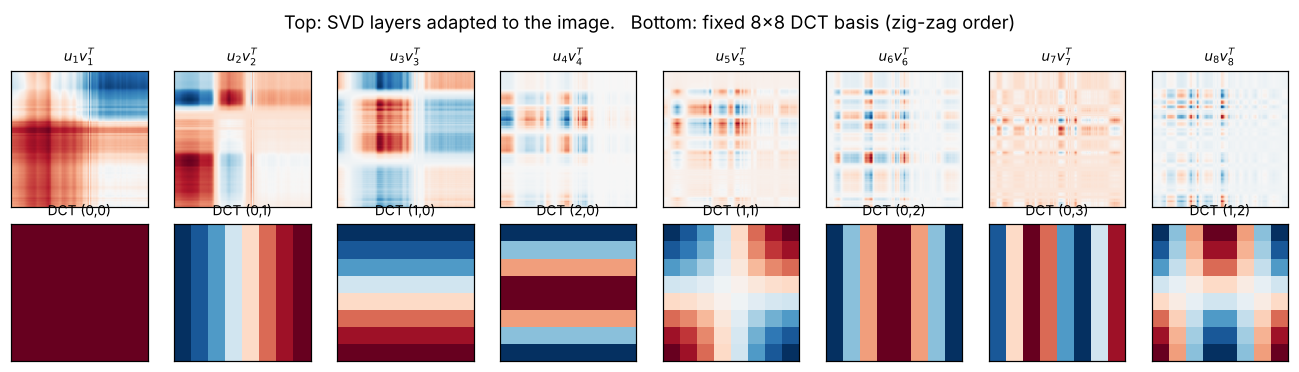

In [4]:
# The DCT basis vs the SVD "basis": first rank-one layers of the cameraman vs the 8x8 DCT basis images
from scipy.fft import idctn
U, s, Vt = numpy_svd(A, 8)
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for i in range(8):
    axes[0, i].imshow(np.outer(U[:, i], Vt[i]), cmap="RdBu")
    axes[0, i].set_title(rf"$u_{{{i+1}}}v_{{{i+1}}}^T$", fontsize=9)
    e = np.zeros((8, 8)); u, v = [(0,0),(0,1),(1,0),(2,0),(1,1),(0,2),(0,3),(1,2)][i]; e[u, v] = 1
    axes[1, i].imshow(idctn(e, norm="ortho"), cmap="RdBu")
    axes[1, i].set_title(f"DCT ({u},{v})", fontsize=9)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("Top: SVD layers adapted to the image.   Bottom: fixed 8x8 DCT basis (zig-zag order)")
plt.tight_layout(); plt.show()

## 6. Experiments

Test images (see `images/make_images.py`):

| image | size | type |
|---|---|---|
| cameraman | 512×512 | grayscale photo |
| astronaut | 512×512 | colour photo |
| text | 172×448 | scanned text |
| cartoon | 256×256 | synthetic: smooth gradient and flat discs |
| checkerboard | 256×256 | synthetic, exactly rank 2 |
| noise | 256×256 | uniform random pixels, no structure |

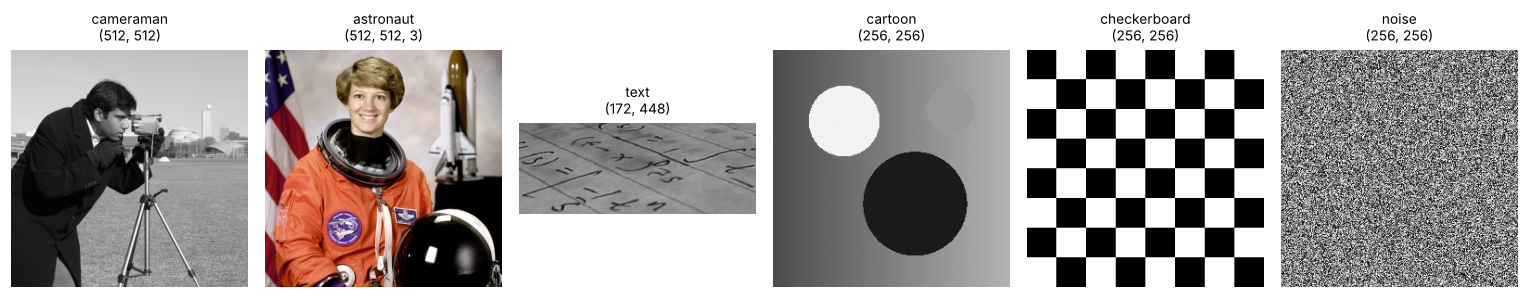

In [5]:
names = ["cameraman", "astronaut", "text", "cartoon", "checkerboard", "noise"]
images = {nm: load_image(IMG / f"{nm}.png", grayscale=(nm != "astronaut")) for nm in names}
gray = {nm: (rgb_to_gray(im) if im.ndim == 3 else im) for nm, im in images.items()}

fig, axes = plt.subplots(1, 6, figsize=(14, 2.8))
for ax, nm in zip(axes, names):
    ax.imshow(images[nm], vmin=0, vmax=1); ax.set_title(f"{nm}\n{images[nm].shape}", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

### Experiment 1: Singular value decay determines compressibility

By Eckart–Young, the relative error of $A_k$ is $\sqrt{1-\mathcal E_k}$. So the whole story is in the spectrum.

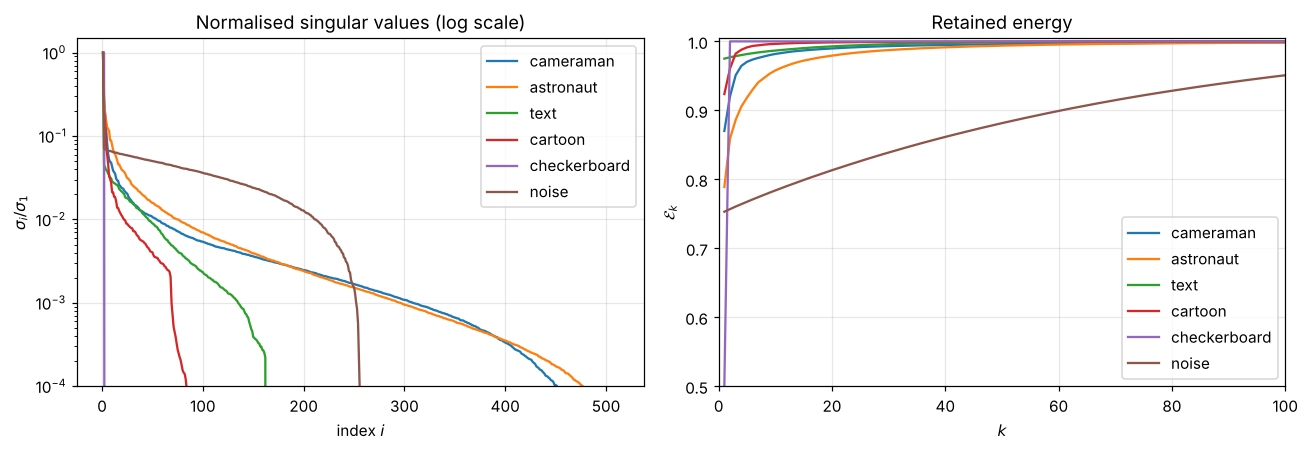

image          rank for 99% energy  rank for 99.9%  k* (break-even)
cameraman                       21             128              255
astronaut                       36             126              255
text                            15              55              124
cartoon                          5              26              127
checkerboard                     2               2              127
noise                          164             213              127


In [6]:
spectra = {nm: np.linalg.svd(g, compute_uv=False) for nm, g in gray.items()}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
for nm, s in spectra.items():
    ax1.semilogy(np.arange(1, len(s) + 1), s / s[0], label=nm)
    ax2.plot(np.arange(1, len(s) + 1), np.cumsum(s**2) / np.sum(s**2), label=nm)
ax1.set(xlabel="index $i$", ylabel=r"$\sigma_i/\sigma_1$", title="Normalised singular values (log scale)",
        ylim=(1e-4, 1.5))
ax2.set(xlabel="$k$", ylabel=r"$\mathcal{E}_k$", title="Retained energy", xlim=(0, 100), ylim=(0.5, 1.005))
ax1.legend(); ax2.legend(loc="lower right")
plt.tight_layout(); plt.show()

print(f"{'image':13s} {'rank for 99% energy':>20s} {'rank for 99.9%':>15s} {'k* (break-even)':>16s}")
for nm, s in spectra.items():
    m_, n_ = gray[nm].shape
    print(f"{nm:13s} {rank_for_energy(s, 0.99):20d} {rank_for_energy(s, 0.999):15d} {break_even_rank(m_, n_):16d}")

**Observations.**
* The **checkerboard** has exactly two non-zero singular values: it is a rank-2 matrix, and $k=2$ reconstructs it perfectly.
* The **cartoon** (smooth and flat regions) and the **photos** decay fast at first and then follow a long, slowly
  decaying tail. Fine texture and edges live in that tail.
* **Noise** has an almost flat spectrum. No small $k$ captures it, and for 99.9% energy we would need a rank far above
  the break-even rank. *A matrix without structure cannot be compressed.* That is exactly what the theory predicts.
* Note that the energy is dominated by $\sigma_1$ (the average brightness). A high energy fraction does not yet
  guarantee a visually good image, which is why we also look at PSNR, SSIM and the pictures themselves.

### Experiment 2: What does a rank-$k$ image look like?

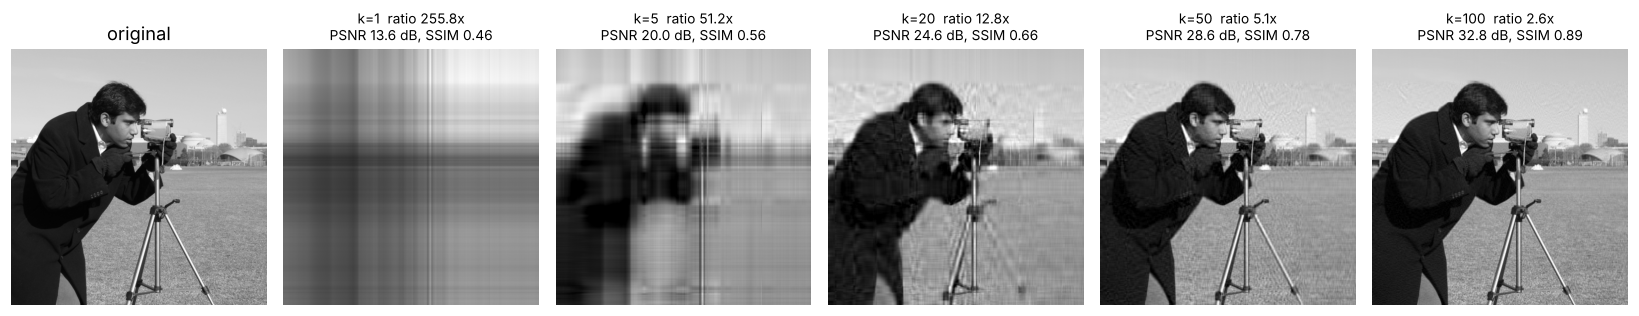

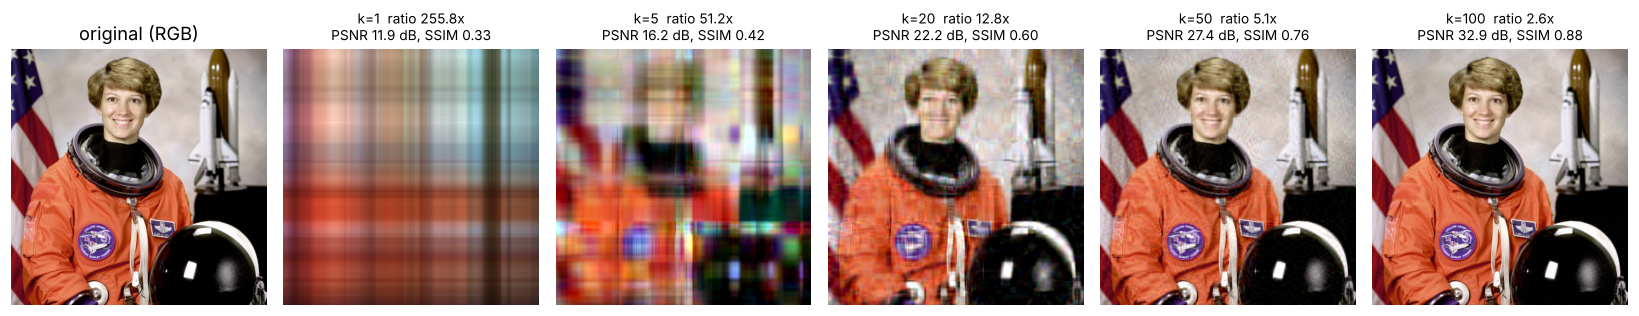

In [7]:
ks = [1, 5, 20, 50, 100]
A = images["cameraman"]; m_, n_ = A.shape
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(15, 3.2))
axes[0].imshow(A, vmin=0, vmax=1); axes[0].set_title("original")
for ax, k in zip(axes[1:], ks):
    Ak = compress_image(A, k)
    ax.imshow(Ak, vmin=0, vmax=1)
    ax.set_title(f"k={k}  ratio {compression_ratio(m_, n_, k):.1f}x\nPSNR {psnr(A, Ak):.1f} dB, SSIM {ssim(A, Ak):.2f}",
                 fontsize=9)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

A = images["astronaut"]; m_, n_, _ = A.shape
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(15, 3.2))
axes[0].imshow(A); axes[0].set_title("original (RGB)")
for ax, k in zip(axes[1:], ks):
    Ak = compress_image(A, k)            # each channel compressed separately -> 3k(m+n+1) values
    ax.imshow(Ak)
    ax.set_title(f"k={k}  ratio {compression_ratio(m_, n_, k):.1f}x\nPSNR {psnr(A, Ak):.1f} dB, SSIM {ssim(A, Ak):.2f}",
                 fontsize=9)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

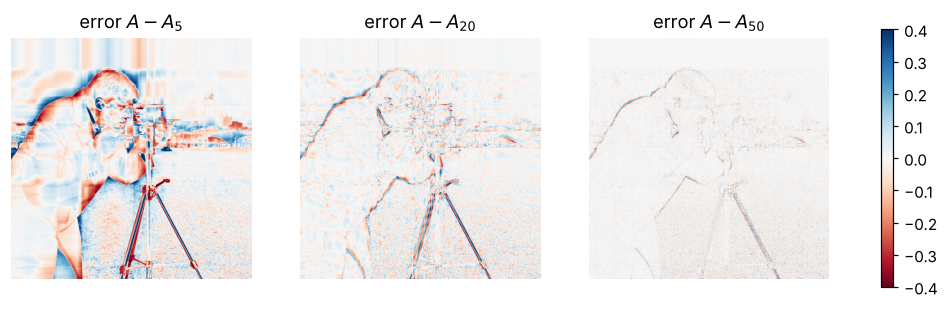

In [8]:
# The error image A - A_k: what the low-rank approximation throws away
A = images["cameraman"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, k in zip(axes, (5, 20, 50)):
    E = A - low_rank_approx(A, k)
    im = ax.imshow(E, cmap="RdBu", vmin=-0.4, vmax=0.4); ax.set_title(f"error $A-A_{{{k}}}$"); ax.axis("off")
fig.colorbar(im, ax=axes, shrink=0.8); plt.show()

**Observations.** With $k=1$ we only see the outer product of one column and one row profile, i.e. horizontal and
vertical "stripes". By $k=20$ (about 13× smaller) the scene is clearly recognisable. At $k=50$ (5× smaller) the
photo is decent, with $\approx 29$ dB PSNR, and at $k=100$ (2.6× smaller) it reaches $\approx 33$ dB. The error images show what remains: mostly **edges and fine texture**,
which are not aligned with rows and columns.

A typical SVD artefact is horizontal and vertical streaking. Diagonal edges are the hardest case, because a
diagonal line has (almost) full rank: the identity matrix $I_N$ has all singular values equal to 1.

### Experiment 3: Numerical verification of the Eckart–Young–Mirsky theorem

1. The measured errors $\|A-A_k\|_2$ and $\|A-A_k\|_F$ must equal the predicted $\sigma_{k+1}$ and $\sqrt{\sum_{i>k}\sigma_i^2}$.
2. No other rank-$k$ matrix should beat $A_k$. As challengers we use (a) $A$ projected onto $k$ random
   directions, $A\,QQ^\top$, (b) the randomized SVD without power iterations, and (c) $A$ with all pixel *columns*
   except $k$ evenly spaced ones replaced by least-squares combinations of them (a "keep $k$ columns" scheme).

max |measured - predicted|  spectral: 2.84e-14   Frobenius: 1.42e-14


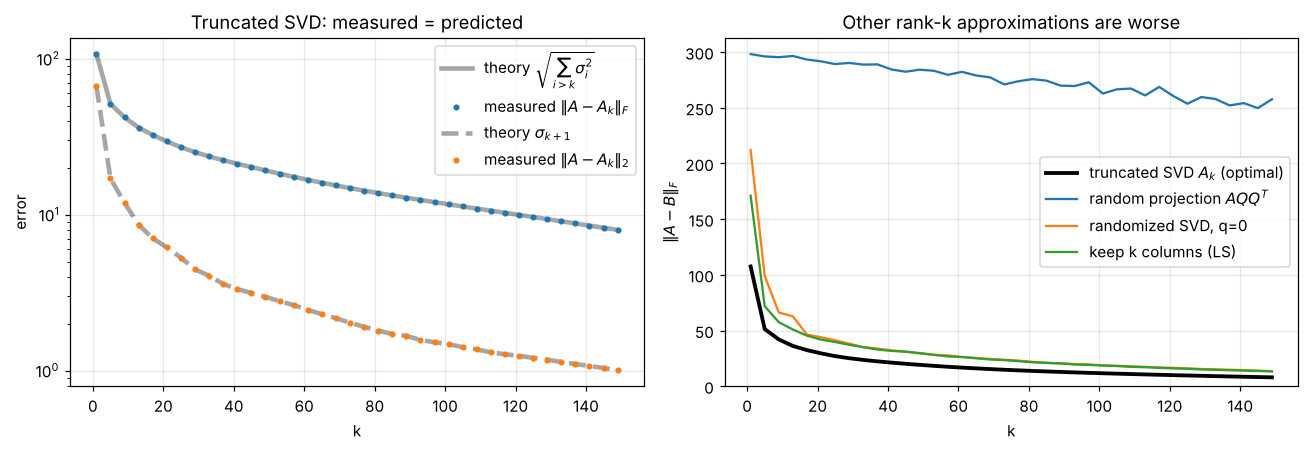

smallest gap (challenger - optimal) over all k: 5.3323  (>= 0 as the theorem requires)


In [9]:
A = gray["cameraman"]; s = spectra["cameraman"]
ks_ = np.arange(1, 151, 4)
meas_2, meas_F, pred_2, pred_F = [], [], [], []
for k in ks_:
    E = A - low_rank_approx(A, k)
    meas_2.append(np.linalg.norm(E, 2)); meas_F.append(np.linalg.norm(E, "fro"))
    p2, pF = theoretical_errors(s, k); pred_2.append(p2); pred_F.append(pF)
print("max |measured - predicted|  spectral: %.2e   Frobenius: %.2e"
      % (np.max(np.abs(np.subtract(meas_2, pred_2))), np.max(np.abs(np.subtract(meas_F, pred_F)))))

chal = {"random projection $AQQ^T$": [], "randomized SVD, q=0": [], "keep k columns (LS)": []}
for k in ks_:
    Q, _ = np.linalg.qr(rng.standard_normal((A.shape[1], k)))
    chal["random projection $AQQ^T$"].append(np.linalg.norm(A - A @ Q @ Q.T))
    U, sv, Vt = randomized_svd(A, k, oversampling=0, power_iters=0, seed=int(k))
    chal["randomized SVD, q=0"].append(np.linalg.norm(A - (U * sv) @ Vt))
    C = A[:, np.linspace(0, A.shape[1] - 1, k).astype(int)]
    X, *_ = np.linalg.lstsq(C, A, rcond=None)
    chal["keep k columns (LS)"].append(np.linalg.norm(A - C @ X))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ax1.semilogy(ks_, pred_F, "k-", lw=3, alpha=0.35, label=r"theory $\sqrt{\sum_{i>k}\sigma_i^2}$")
ax1.semilogy(ks_, meas_F, "C0.", label=r"measured $\|A-A_k\|_F$")
ax1.semilogy(ks_, pred_2, "k--", lw=3, alpha=0.35, label=r"theory $\sigma_{k+1}$")
ax1.semilogy(ks_, meas_2, "C1.", label=r"measured $\|A-A_k\|_2$")
ax1.set(xlabel="k", ylabel="error", title="Truncated SVD: measured = predicted"); ax1.legend()
ax2.plot(ks_, meas_F, "k-", lw=2.5, label="truncated SVD $A_k$ (optimal)")
for name, errs in chal.items():
    ax2.plot(ks_, errs, label=name)
ax2.set(xlabel="k", ylabel=r"$\|A-B\|_F$", title="Other rank-k approximations are worse", ylim=(0, None))
ax2.legend(); plt.tight_layout(); plt.show()

worst_margin = min(np.min(np.array(e) - np.array(meas_F)) for e in chal.values())
print(f"smallest gap (challenger - optimal) over all k: {worst_margin:.4f}  (>= 0 as the theorem requires)")

**Result.** The measured and predicted errors agree to machine precision for every $k$, in both norms. All challengers
stay above the optimal curve. The "keep $k$ columns" scheme and the randomized SVD without power iterations come
close for larger $k$, but neither ever crosses the optimum. This is the theorem confirmed numerically.

### Experiment 4: SVD vs block DCT (JPEG idea): quality per stored number

We give all methods the same budget, measured as the fraction of stored numbers relative to $mn$, and compare PSNR and SSIM.

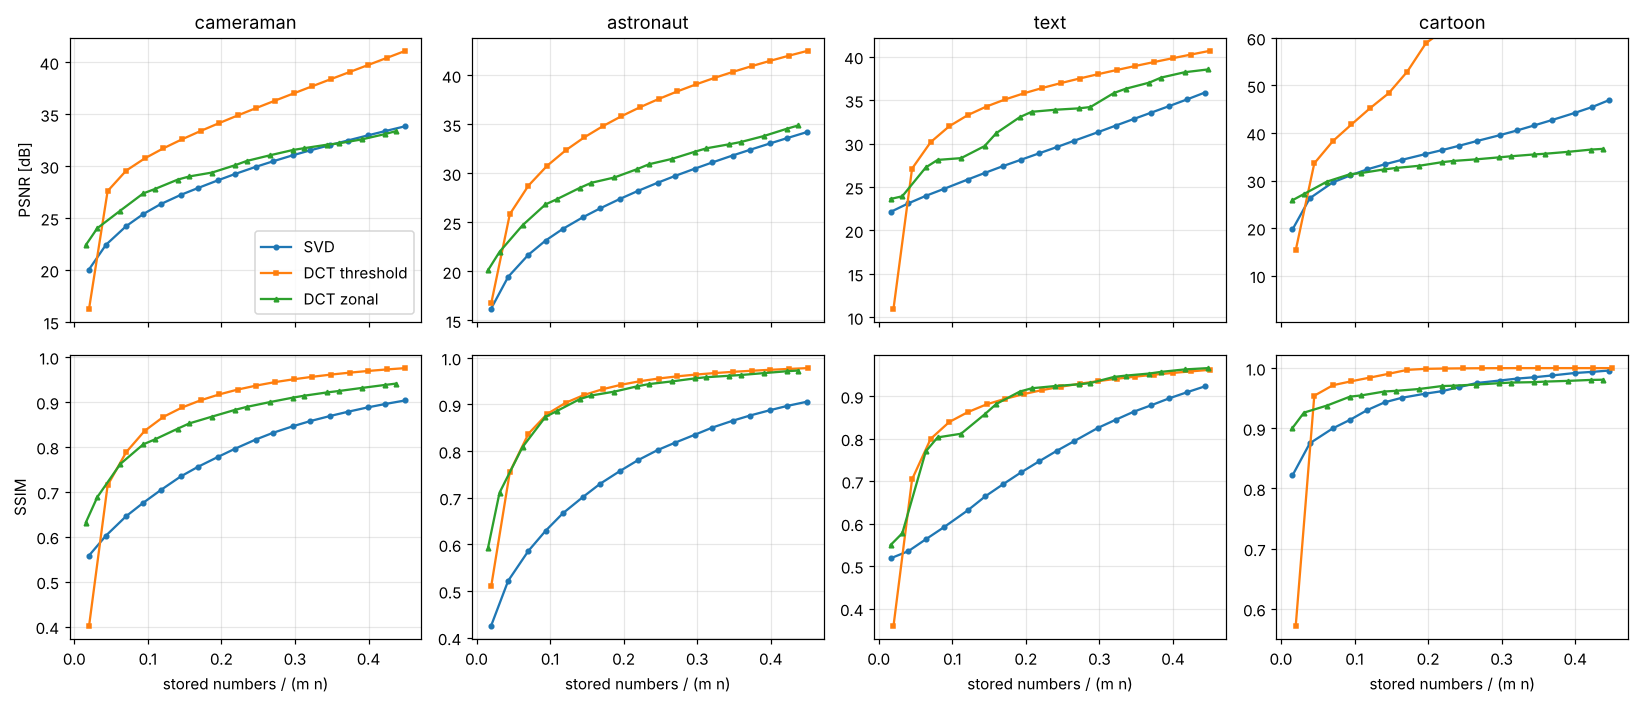

In [10]:
def rate_distortion(img, ks, budgets_frac):
    m_, n_ = img.shape[:2]; chans = 1 if img.ndim == 2 else 3
    res = {"SVD": [], "DCT threshold": [], "DCT zonal": []}
    for k in ks:
        out = compress_image(img, k)
        res["SVD"].append((storage_cost(m_, n_, k, chans) / (chans * m_ * n_), psnr(img, out), ssim(img, out)))
    for f in budgets_frac:
        budget = int(f * m_ * n_)
        for mode, key in (("threshold", "DCT threshold"), ("zonal", "DCT zonal")):
            out, stored = dct_compress_image(img, budget, mode=mode)
            res[key].append((stored / (chans * m_ * n_), psnr(img, out), ssim(img, out)))
    return {key: np.array(v) for key, v in res.items()}

test_imgs = ["cameraman", "astronaut", "text", "cartoon"]
fracs = np.linspace(0.02, 0.45, 18)
rd = {}
for nm in test_imgs:
    m_, n_ = images[nm].shape[:2]
    ks = np.unique(np.clip((fracs * m_ * n_ / (m_ + n_ + 1)).astype(int), 1, None))
    rd[nm] = rate_distortion(images[nm], ks, fracs)

fig, axes = plt.subplots(2, len(test_imgs), figsize=(15, 6.5), sharex=True)
for j, nm in enumerate(test_imgs):
    for key, style in (("SVD", "o-"), ("DCT threshold", "s-"), ("DCT zonal", "^-")):
        r = rd[nm][key]
        axes[0, j].plot(r[:, 0], r[:, 1], style, ms=3, label=key)
        axes[1, j].plot(r[:, 0], r[:, 2], style, ms=3, label=key)
    axes[0, j].set_title(nm); axes[1, j].set_xlabel("stored numbers / (m n)")
    axes[0, j].set_ylim(top=min(axes[0, j].get_ylim()[1], 60))   # lossless reconstruction = infinite PSNR
axes[0, 0].set_ylabel("PSNR [dB]"); axes[1, 0].set_ylabel("SSIM"); axes[0, 0].legend()
plt.tight_layout(); plt.show()

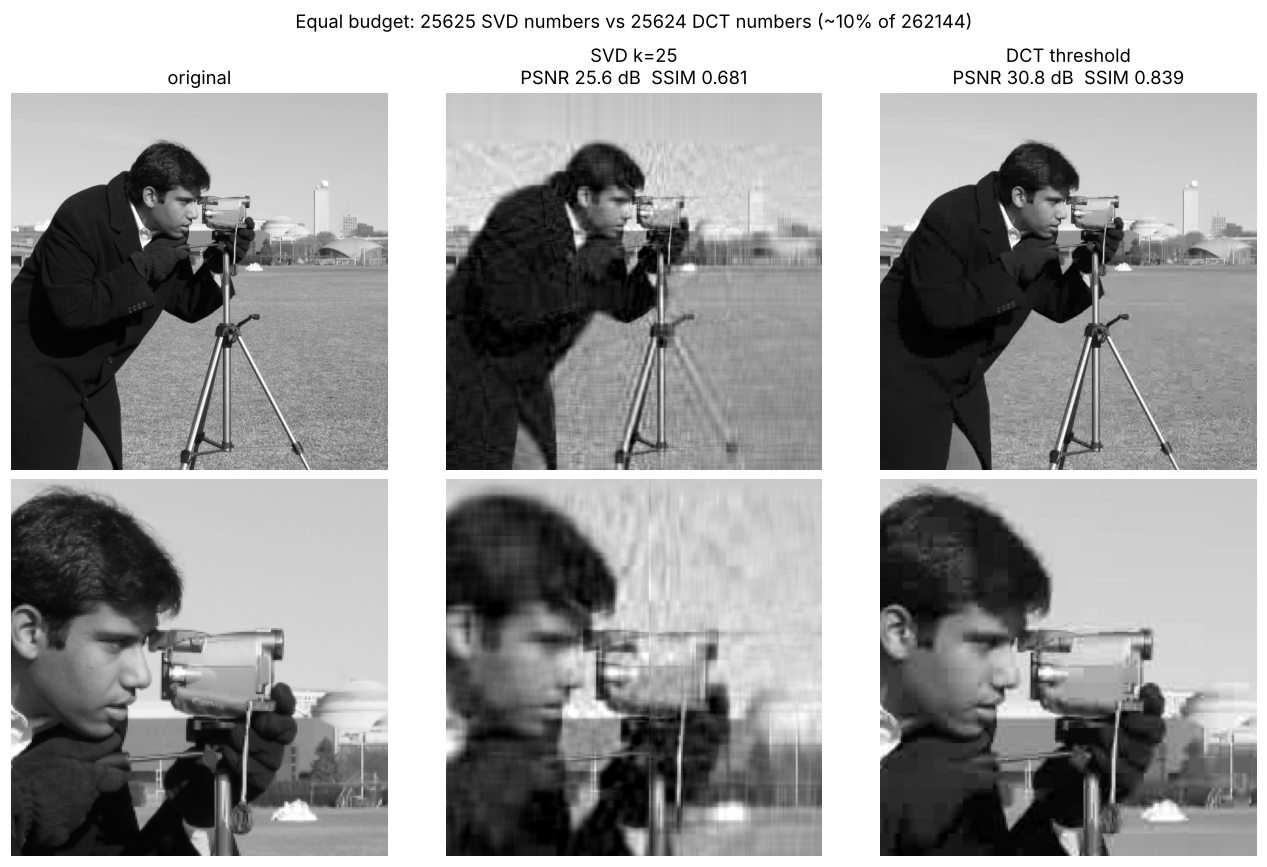

In [11]:
# Same budget (about 10% of the numbers), side by side
nm = "cameraman"; A = images[nm]; m_, n_ = A.shape
k = int(0.10 * m_ * n_ / (m_ + n_ + 1))
svd_img = compress_image(A, k)
dct_img, stored = dct_compress_image(A, storage_cost(m_, n_, k), mode="threshold")
crop = (slice(60, 260), slice(180, 380))
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for col, (title, im) in enumerate([("original", A), (f"SVD k={k}", svd_img), ("DCT threshold", dct_img)]):
    axes[0, col].imshow(im, vmin=0, vmax=1)
    axes[1, col].imshow(im[crop], vmin=0, vmax=1)
    sub = "" if col == 0 else f"\nPSNR {psnr(A, im):.1f} dB  SSIM {ssim(A, im):.3f}"
    axes[0, col].set_title(title + sub)
for ax in axes.ravel(): ax.axis("off")
plt.suptitle(f"Equal budget: {storage_cost(m_, n_, k)} SVD numbers vs {stored} DCT numbers (~10% of {m_*n_})")
plt.tight_layout(); plt.show()

**Observations.**
* On all four images, the **DCT with thresholding beats the SVD at the same budget** in both PSNR and SSIM,
  even though we charge the DCT twice for every coefficient (value plus position). On the photos the gap is
  about 5–8 dB. Only at the smallest budget (about 2% of the numbers), where paying for positions hurts the DCT
  most, is the SVD ahead on the cameraman, text and cartoon. (On the astronaut the DCT still wins narrowly.)
* On the cartoon, the thresholded DCT becomes exactly **lossless** at around 37% of the budget (the PSNR curve is
  cut off at 60 dB, which it passes at about 22%). Flat regions produce exactly zero DCT coefficients, so only the blocks on the disc
  edges need to be stored.
* This does **not** contradict Eckart–Young. The theorem is about the best *rank-$k$ matrix*, while a sparse DCT
  representation is not a low-rank matrix. The DCT wins because natural images are *locally smooth*: in every
  $8\times8$ block, almost all energy sits in a few low-frequency coefficients, wherever the edges are. The SVD
  has to describe the *whole* image with global row and column profiles, so a single diagonal edge costs many ranks.
* Zonal DCT (fixed low frequencies, no positions) is simpler and weaker than adaptive thresholding. On the
  cameraman it is 1.5–2.5 dB ahead of the SVD at small budgets and about equal above ~35%. On the cartoon the SVD
  is ahead in PSNR above ~10% and in SSIM above ~27%. Zonal DCT does best at small budgets, where it keeps
  local detail everywhere instead of producing global streaks.
* The SVD is only unbeatable on images with **global, axis-aligned row and column structure**, such as the
  checkerboard (exact at rank 2, Experiment 5). Its advantage is a basis adapted to the image; its weakness is
  that the basis is global.

### Experiment 5: Structure vs noise

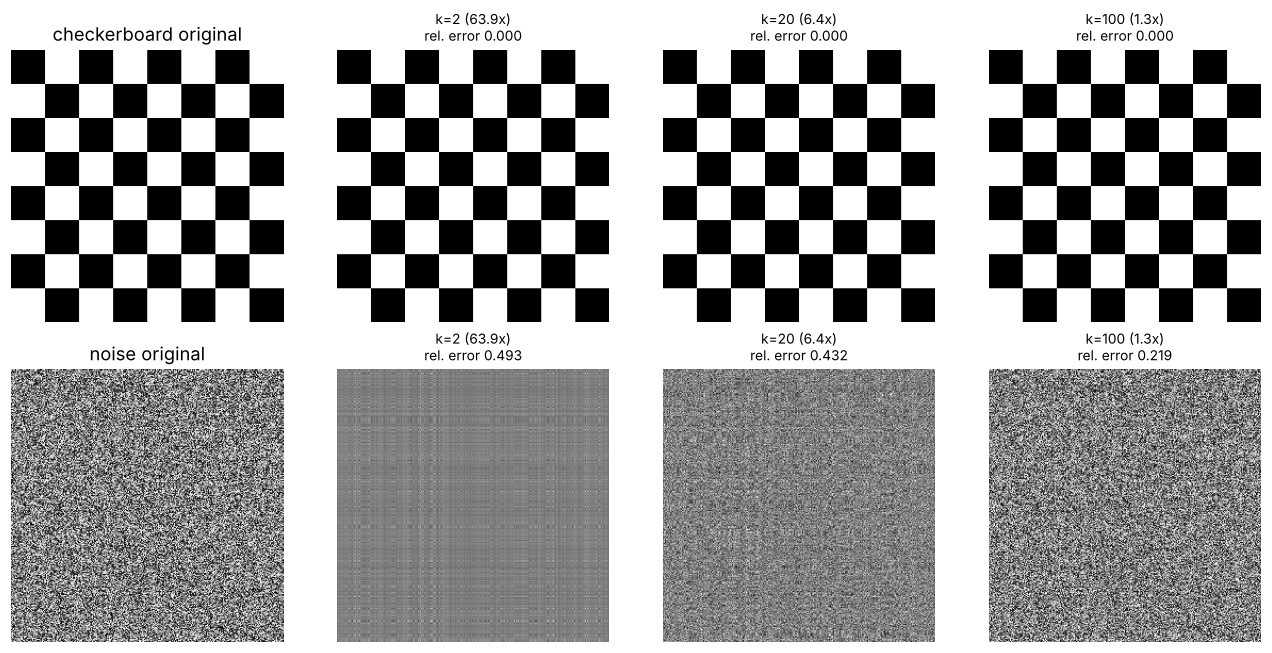

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for row, nm in enumerate(["checkerboard", "noise"]):
    A = images[nm]; m_, n_ = A.shape
    axes[row, 0].imshow(A, vmin=0, vmax=1); axes[row, 0].set_title(f"{nm} original")
    for ax, k in zip(axes[row, 1:], (2, 20, 100)):
        Ak = compress_image(A, k); ax.imshow(Ak, vmin=0, vmax=1)
        ax.set_title(f"k={k} ({compression_ratio(m_, n_, k):.1f}x)\nrel. error {relative_frobenius_error(A, Ak):.3f}",
                     fontsize=9)
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

**Result.** The checkerboard is reproduced **exactly** at $k=2$, a 64× compression with zero error. For noise, even
$k=100$ (already 1.3×, close to the break-even point) leaves a large error. The rank-$k$ approximation of noise is just a blurred grey
mess, because a random matrix spreads its energy evenly over all singular values. This is the information-theoretic
side of compression: *you can only compress structure.*

### Experiment 6: Convergence of our power iteration

Theory (Section 5.1): the angle between the iterate and $v_1$ shrinks like $(\sigma_2/\sigma_1)^{2t}$, and triplet $j$
needs about $\ln\varepsilon/(2\ln(\sigma_{j+1}/\sigma_j))$ iterations.

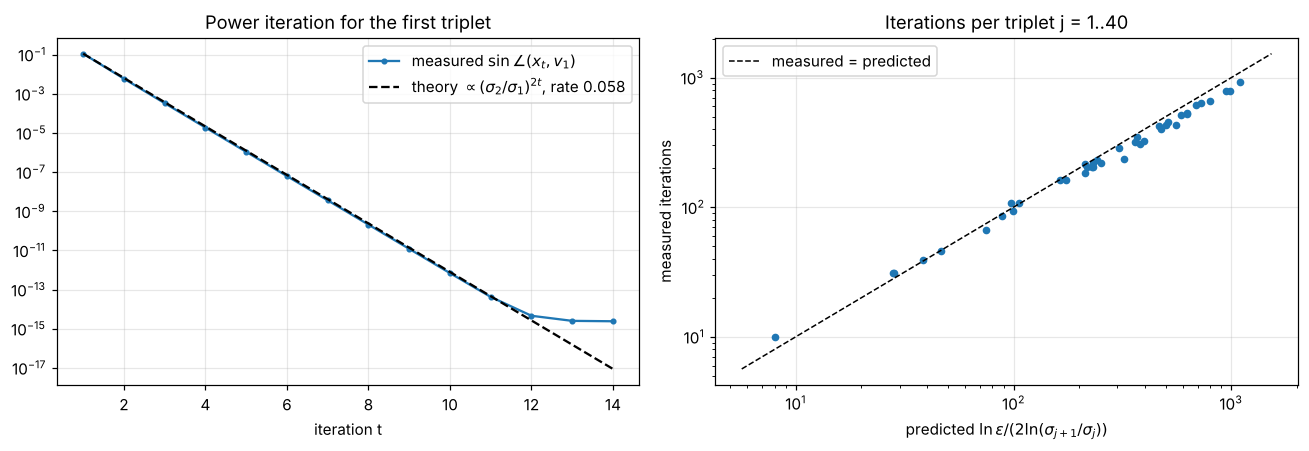

sigma_2/sigma_1 = 0.2403; total iterations for k=40: 12573, all converged: True
max relative error of singular values vs numpy: 2.05e-15


In [13]:
A = gray["cameraman"]
U_ref, s_ref, Vt_ref = np.linalg.svd(A, full_matrices=False)

def angle_history(A, v_true, ratio_target_iters=60, seed=0):
    x = np.random.default_rng(seed).standard_normal(A.shape[1]); x /= np.linalg.norm(x)
    hist = []
    for _ in range(ratio_target_iters):
        x = A.T @ (A @ x); x /= np.linalg.norm(x)
        hist.append(np.linalg.norm(x - (x @ v_true) * v_true))  # sin of the angle to v_1 (stable formula)
    return np.array(hist)

hist = angle_history(A, Vt_ref[0], 14)
t = np.arange(1, len(hist) + 1)
rate = (s_ref[1] / s_ref[0]) ** 2

# all triplets j = 1..40: the number of iterations should follow the gap sigma_{j+1}/sigma_j
U, s, Vt, info = power_svd_with_info(A, 40, tol=1e-10)
ratios = s_ref[1:41] / s_ref[:40]
predicted = np.log(1e-10) / (2 * np.log(ratios))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ax1.semilogy(t, hist, "o-", ms=3, label=r"measured $\sin\angle(x_t, v_1)$")
ax1.semilogy(t, hist[0] / rate * rate ** t, "k--", label=rf"theory $\propto(\sigma_2/\sigma_1)^{{2t}}$, rate {rate:.3f}")
ax1.set(xlabel="iteration t", title="Power iteration for the first triplet"); ax1.legend()
ax2.loglog(predicted, info.iterations, "o", ms=4)
lim = [min(predicted.min(), min(info.iterations)) * 0.7, max(predicted.max(), max(info.iterations)) * 1.4]
ax2.loglog(lim, lim, "k--", lw=1, label="measured = predicted")
ax2.set(xlabel=r"predicted $\ln\varepsilon / (2\ln(\sigma_{j+1}/\sigma_j))$", ylabel="measured iterations",
        title="Iterations per triplet j = 1..40"); ax2.legend()
plt.tight_layout(); plt.show()

print(f"sigma_2/sigma_1 = {s_ref[1]/s_ref[0]:.4f}; total iterations for k=40: {info.total_iterations}, "
      f"all converged: {all(info.converged)}")
print(f"max relative error of singular values vs numpy: {np.max(np.abs(s - s_ref[:40]) / s_ref[:40]):.2e}")

**Result.** The measured angle follows the predicted straight line on the log plot almost exactly, so convergence
is linear with rate $(\sigma_2/\sigma_1)^2\approx0.058$, until it reaches machine precision ($\sim10^{-16}$) after
about 12 iterations. For later triplets the number of iterations follows the prediction from the
**spectral gap**: when two consecutive singular values are close, hundreds or thousands of iterations are needed.
This is the main weakness of the simple power method. Our implementation still reproduces NumPy's singular values
to about $10^{-15}$ relative accuracy.

### Experiment 7: Accuracy of the randomized SVD

Oversampling $p$ and power iterations $q$ are the knobs. We measure how far the error is above the Eckart–Young optimum.

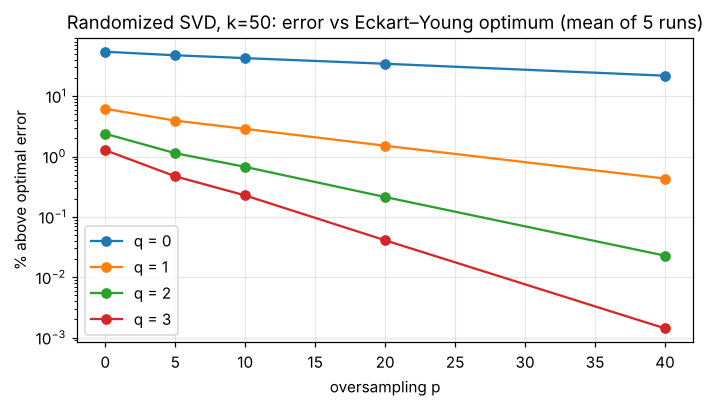

excess error in % (rows q=0..3, columns p=[0, 5, 10, 20, 40]):
[[5.4281e+01 4.7483e+01 4.2596e+01 3.4352e+01 2.1796e+01]
 [6.1640e+00 3.9290e+00 2.8680e+00 1.5080e+00 4.3100e-01]
 [2.3820e+00 1.1350e+00 6.7300e-01 2.1300e-01 2.3000e-02]
 [1.2730e+00 4.7000e-01 2.2700e-01 4.1000e-02 1.0000e-03]]


In [14]:
A = gray["cameraman"]; s_all = spectra["cameraman"]
k = 50; opt = theoretical_errors(s_all, k)[1]
ps = [0, 5, 10, 20, 40]; qs = [0, 1, 2, 3]
excess = np.zeros((len(qs), len(ps)))
for i, q in enumerate(qs):
    for j, p in enumerate(ps):
        errs = []
        for seed in range(5):
            U, s, Vt = randomized_svd(A, k, oversampling=p, power_iters=q, seed=seed)
            errs.append(np.linalg.norm(A - (U * s) @ Vt))
        excess[i, j] = 100 * (np.mean(errs) / opt - 1)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for i, q in enumerate(qs):
    ax.plot(ps, excess[i], "o-", label=f"q = {q}")
ax.set(xlabel="oversampling p", ylabel="% above optimal error", yscale="log",
       title=f"Randomized SVD, k={k}: error vs Eckart–Young optimum (mean of 5 runs)")
ax.legend(); plt.tight_layout(); plt.show()
print("excess error in % (rows q=0..3, columns p=" + str(ps) + "):"); print(np.round(excess, 3))

**Result.** Without power iterations ($q=0$), the randomized SVD is 20–55% worse than optimal, because the
spectrum of an image decays slowly and the random subspace "leaks" into the tail. Oversampling helps (at $q=0$, going from $p=0$ to $p=40$ cuts the excess from 54% to 22%), but far less
than a single power iteration. Power iterations are what matters: $q=1$ gives about 3%, and $q=2$ with $p=10$ gives 0.7% above the optimum,
while $q=3,\ p=20$ gives 0.04%. This matches the recommendation of Halko et al. to use $q=1$–$2$ for slowly decaying spectra.

### Experiment 8: Running time

We compare `numpy.linalg.svd` (full SVD, then truncate), our power iteration and our randomized SVD
($p=10,\ q=2$) on grayscale images of increasing size, all computing the top $k=20$ triplets.
Then we vary $k$ at a fixed size of 512×512.

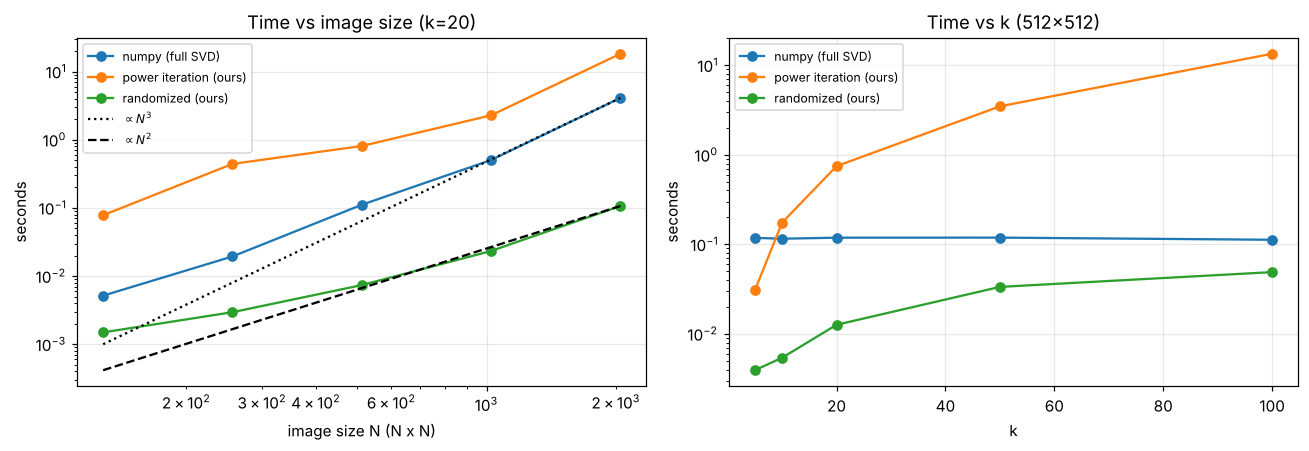

     N          numpy (full SVD)    power iteration (ours)         randomized (ours)
   128                    0.0052                    0.0782                    0.0015
   256                    0.0194                    0.4419                    0.0030
   512                    0.1112                    0.8095                    0.0074
  1024                    0.5038                    2.2811                    0.0234
  2048                    4.1035                   18.2568                    0.1066


In [15]:
from skimage.transform import resize

def timeit(fn, repeat=3):
    best = np.inf
    for _ in range(repeat):
        t0 = time.perf_counter(); fn(); best = min(best, time.perf_counter() - t0)
    return best

base = gray["astronaut"]
sizes = [128, 256, 512, 1024, 2048]
k = 20
times = {"numpy (full SVD)": [], "power iteration (ours)": [], "randomized (ours)": []}
for N in sizes:
    A = resize(base, (N, N), anti_aliasing=True)
    rep = 1 if N >= 1024 else 3
    times["numpy (full SVD)"].append(timeit(lambda: numpy_svd(A, k), rep))
    times["power iteration (ours)"].append(timeit(lambda: power_svd(A, k, tol=1e-8), rep))
    times["randomized (ours)"].append(timeit(lambda: randomized_svd(A, k), rep))

ks_t = [5, 10, 20, 50, 100]
A = gray["cameraman"]
times_k = {"numpy (full SVD)": [], "power iteration (ours)": [], "randomized (ours)": []}
for kk in ks_t:
    times_k["numpy (full SVD)"].append(timeit(lambda: numpy_svd(A, kk)))
    times_k["power iteration (ours)"].append(timeit(lambda: power_svd(A, kk, tol=1e-8), 1))
    times_k["randomized (ours)"].append(timeit(lambda: randomized_svd(A, kk)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
for name in times:
    ax1.loglog(sizes, times[name], "o-", label=name)
    ax2.semilogy(ks_t, times_k[name], "o-", label=name)
ax1.loglog(sizes, times["numpy (full SVD)"][-1] * (np.array(sizes) / sizes[-1]) ** 3, "k:", label=r"$\propto N^3$")
ax1.loglog(sizes, times["randomized (ours)"][-1] * (np.array(sizes) / sizes[-1]) ** 2, "k--", label=r"$\propto N^2$")
ax1.set(xlabel="image size N (N x N)", ylabel="seconds", title=f"Time vs image size (k={k})"); ax1.legend(fontsize=8)
ax2.set(xlabel="k", ylabel="seconds", title="Time vs k (512x512)"); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'N':>6s}" + "".join(f"{nm:>26s}" for nm in times))
for i, N in enumerate(sizes):
    print(f"{N:6d}" + "".join(f"{times[nm][i]:26.4f}" for nm in times))

**Result.**
* The full LAPACK SVD grows like $N^3$. It is extremely well optimised, so it is fast for small images, but it
  computes *all* $N$ triplets even though we need 20.
* The **randomized SVD grows like $N^2$** (a constant number of passes over the pixels) and was the fastest method
  at every size: about 12× faster than LAPACK at 512×512 and about 40× faster at 2048×2048, while staying within
  1% of the optimal error (Experiment 7). Its cost grows only mildly with $k$.
* Our **power iteration** is the slowest except for very small $k$: for $k=5$ it beats the full SVD, because it
  computes only what it needs. It needs many matrix-vector products when singular values are close (Experiment 6),
  and its cost grows quickly with $k$ because each triplet is computed separately. Its value is that it is simple,
  transparent and correct, but it is not the method of choice in practice.

## 7. Conclusions

**Answers to the questions from Section 1.**

1. **What is the best rank-$k$ approximation?** The truncated SVD $A_k=\sum_{i\le k}\sigma_iu_iv_i^\top$. We proved
   (Eckart–Young–Mirsky) that it is optimal in both the spectral and the Frobenius norm, with errors $\sigma_{k+1}$ and
   $\sqrt{\sum_{i>k}\sigma_i^2}$. Experiment 3 confirmed both identities to machine precision, and no challenger
   beat it.
2. **How well does it compress images?** That is decided by the decay of the singular values (Experiment 1).
   Structured images compress extremely well (the checkerboard exactly at $k=2$). Photos give acceptable
   quality (27–29 dB) at about 5× compression and ≈33 dB at 2.6×, and they stay recognisable at 10–25×. Noise cannot be
   compressed at all.
   Storage only pays off below the break-even rank $k^*\approx mn/(m+n)$.
3. **How do we compute it?**
   * Our **power iteration** with deflation reproduces NumPy's singular values to $\sim10^{-15}$. Its convergence
     rate $(\sigma_{j+1}/\sigma_j)^2$ was confirmed experimentally, and it explains why the method is slow on images
     with clustered singular values.
   * Our **randomized SVD** is within 1% of the optimum with $p=10$, $q=2$. It scales as $O(N^2k)$ and was the
     fastest method at every image size (about 40× faster than LAPACK at 2048×2048).
   * **LAPACK** is the most accurate general-purpose choice and the right one when all triplets are needed.
4. **SVD vs DCT (JPEG).** At the same number of stored values, the thresholded block DCT gives better PSNR and
   SSIM on every test image (about 5–8 dB on the photos), except at the very smallest budgets. Being optimal among *low-rank* matrices is not the same as being optimal among *all*
   compact representations. Natural images are *locally* smooth rather than globally low-rank, and that is why
   JPEG uses the DCT. The SVD wins only for globally low-rank, axis-aligned content. Its real strengths are a basis
   **adapted to the data** and a provable optimality guarantee, which is why it is used in data analysis (PCA,
   recommender systems, denoising) more than in image codecs.

**Limitations and possible extensions.**
* We count stored *numbers*. Real codecs also quantise them and use entropy coding (the bits per number differ).
  Quantising $U_k$, $V_k$ is a natural next step.
* Compressing RGB channels separately ignores the correlation between colours. Converting to a luminance/chroma
  space (YCbCr) first, and giving the chroma channels a lower rank, would help, as in JPEG.
* **Block-wise SVD** (an SVD on each tile) combines the locality of the DCT with the adaptivity of the SVD.
  Comparing it with the DCT would be a natural follow-up.
* Faster SVD algorithms: block power (subspace) iteration and Lanczos/Krylov methods converge much faster than
  single-vector power iteration when singular values are clustered.

## 8. References

1. C. Eckart, G. Young. *The approximation of one matrix by another of lower rank.* Psychometrika 1(3), 1936.
2. L. Mirsky. *Symmetric gauge functions and unitarily invariant norms.* Quart. J. Math. 11, 1960.
3. N. Halko, P.-G. Martinsson, J. A. Tropp. *Finding structure with randomness: probabilistic algorithms for
   constructing approximate matrix decompositions.* SIAM Review 53(2), 2011.
4. L. N. Trefethen, D. Bau III. *Numerical Linear Algebra.* SIAM, 1997 (Lectures 4–5, 27).
5. G. Strang. *Introduction to Linear Algebra*, 5th ed., Wellesley-Cambridge, 2016 (Chapter 7).
6. G. K. Wallace. *The JPEG still picture compression standard.* IEEE Trans. Consumer Electronics 38(1), 1992.
7. Test images: `skimage.data` (scikit-image project); synthetic images generated in `images/make_images.py`.